# 04 — Volatility Targeting et contrôle du risque (Projet 3)

On ne cherche **pas** à prédire le rendement : on ajuste la **taille** de l'exposition selon le risque observé. Quand la volatilité réalisée monte, l'exposition baisse ; quand elle baisse, l'exposition remonte, plafonnée à 100 % (aucun levier). Le reste va au cash.

```text
exposition = clip(volatilité_cible / volatilité_réalisée, min, max)
```

> Notebook **éducatif**. Aucun ordre exécuté, décision manuelle. Données Yahoo Finance (non officielles).

## 1. Initialisation

In [1]:
import sys
from pathlib import Path


def find_project_root(markers=("src", "config")) -> Path:
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if all((candidate / m).is_dir() for m in markers):
            return candidate
    raise RuntimeError("Racine du projet introuvable.")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
for folder in ["src", "data", "config", "tests"]:
    assert (PROJECT_ROOT / folder).is_dir(), f"Dossier manquant : {folder}"
print("Racine :", PROJECT_ROOT)

Racine : C:\Users\degar\OneDrive - De Vinci Higher Education (DVHE)\Perso\Projet Investissement\personal-quant-lab


## 2. Imports et versions

In [2]:
%matplotlib inline
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import download_prices, load_prices, save_prices, load_tickers_from_yaml, validate_prices
from src.features import to_monthly_prices, rolling_annualized_volatility
from src.signals import build_momentum_weights, CASH_COLUMN
from src.portfolio import build_vol_targeted_weights, compute_target_exposure, apply_volatility_target
from src.backtest import backtest_monthly_allocation, buy_and_hold
from src.metrics import performance_summary, compute_drawdown, yearly_returns

for dep in ("pandas", "numpy", "matplotlib", "yfinance"):
    assert importlib.util.find_spec(dep) is not None, f"Dépendance manquante : {dep}"
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.4.6


## 3. Chargement des données

On réutilise le dataset local du Projet 2 (`momentum_universe.csv`) ; téléchargement uniquement si absent. Univers : ETF PEA à historique complet.

In [3]:
BENCHMARK = "CW8.PA"
UNIVERSE_CSV = PROJECT_ROOT / "data" / "processed" / "momentum_universe.csv"

if UNIVERSE_CSV.exists():
    prices = load_prices(UNIVERSE_CSV)
    print("Chargé depuis", UNIVERSE_CSV.relative_to(PROJECT_ROOT))
else:
    etfs = [t for t in load_tickers_from_yaml(PROJECT_ROOT / "config" / "assets.yaml") if t.endswith(".PA")]
    prices = validate_prices(download_prices(etfs, start="2015-01-01"))
    save_prices(prices, UNIVERSE_CSV)
    print("Téléchargé et sauvegardé.")

# On conserve les ETF à historique complet (mêmes règles qu'au Projet 2).
monthly_all = to_monthly_prices(prices)
kept = [c for c in prices.columns if monthly_all[c].notna().sum() >= 34]
universe = prices[kept].copy()
monthly_prices = to_monthly_prices(universe)
print("Univers retenu :", kept)
print("Période :", universe.dropna(how="any").index.min().date(), "->", universe.dropna(how="any").index.max().date())

Chargé depuis data\processed\momentum_universe.csv
Univers retenu : ['CW8.PA', 'ESE.PA']
Période : 2015-01-02 -> 2026-07-08


## 4. Baselines

Buy & Hold du benchmark et Momentum principal (12-1 + MA10), avec leurs métriques de référence (mensuel, frais 0,10 %).

In [4]:
IC, PPY = 10_000.0, 12
TC = 0.001
LOOKBACK, SKIP, MA_WINDOW = 12, 1, 10


def momentum_strategy(daily, lookback, skip, ma, top_n, tc, use_trend=True):
    res = build_momentum_weights(daily, lookback, skip, ma, top_n, use_trend_filter=use_trend)
    bt = backtest_monthly_allocation(res["monthly_prices"], res["executed_weights"],
                                     initial_capital=IC, transaction_cost=tc)
    return res, bt


def vol_targeted_strategy(res, target_vol, window, tc):
    vt = build_vol_targeted_weights(res["monthly_prices"], res["executed_weights"],
                                    target_volatility=target_vol, vol_window=window)
    bt = backtest_monthly_allocation(res["monthly_prices"], vt["final_weights"],
                                     initial_capital=IC, transaction_cost=tc)
    return vt, bt


monthly_bench = to_monthly_prices(universe[BENCHMARK]).dropna()
bench = buy_and_hold(monthly_bench, initial_capital=IC)
base_res, base_bt = momentum_strategy(universe, LOOKBACK, SKIP, MA_WINDOW, 1, TC)

print("Buy & Hold :"); print(performance_summary(bench["Returns"].dropna(), bench["Equity Curve"], periods_per_year=PPY).round(4))
print("\nMomentum 12-1 + MA10 :"); print(performance_summary(base_bt["Net Return"].dropna(), base_bt["Equity Curve"], periods_per_year=PPY).round(4))

Buy & Hold :
CAGR                 0.1117
Volatility           0.1323
Sharpe               0.8699
Max Drawdown        -0.1861
Best Year            0.3234
Worst Year          -0.1374
Final Capital    33804.1845
dtype: float64

Momentum 12-1 + MA10 :
CAGR                 0.0872
Volatility           0.1090
Sharpe               0.8237
Max Drawdown        -0.1658
Best Year            0.4126
Worst Year          -0.1658
Final Capital    26335.8171
dtype: float64


## 5. Volatilité réalisée

On calcule la volatilité annualisée glissante des **rendements de la stratégie Momentum de base**, pour trois fenêtres (3, 6, 12 mois). La fenêtre courte réagit vite mais est bruitée ; la longue est plus lisse mais réagit tard. **Choix principal : 3 mois.**

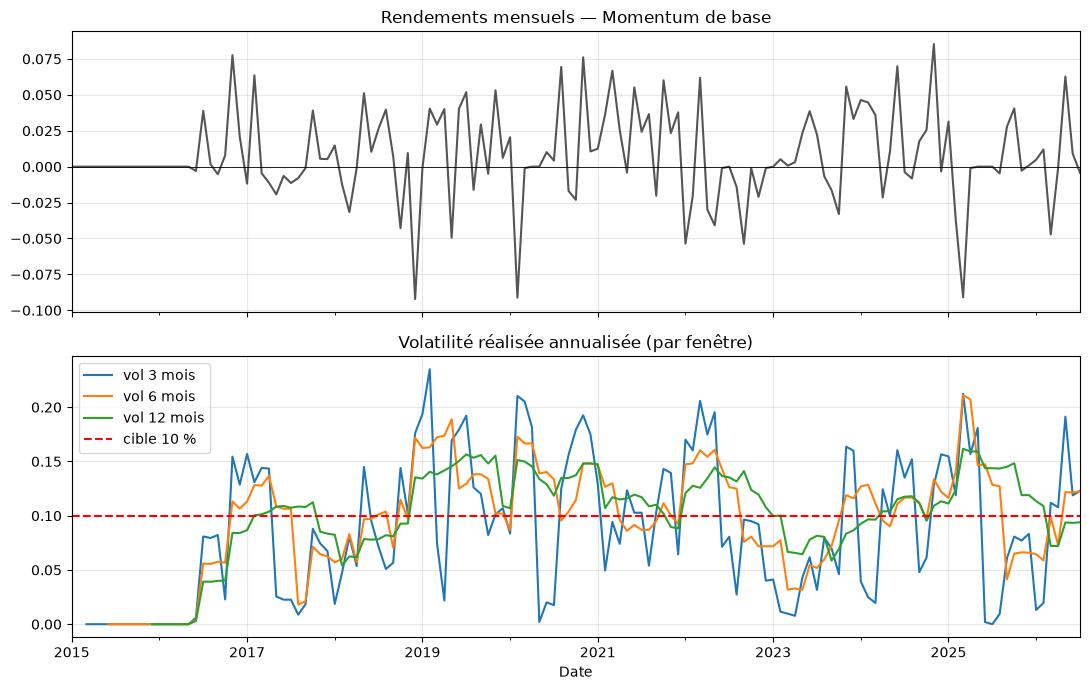

Volatilité réalisée moyenne par fenêtre :
3 mois     0.0871
6 mois     0.0969
12 mois    0.1040
dtype: float64


In [5]:
base_returns = base_bt["Net Return"]

vols = {w: rolling_annualized_volatility(base_returns, window=w, periods_per_year=PPY) for w in (3, 6, 12)}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
base_returns.plot(ax=ax1, color="#555"); ax1.axhline(0, color="black", lw=0.6)
ax1.set_title("Rendements mensuels — Momentum de base"); ax1.grid(True, alpha=0.3)
for w, v in vols.items():
    v.plot(ax=ax2, label=f"vol {w} mois")
ax2.axhline(0.10, color="red", ls="--", label="cible 10 %")
ax2.set_title("Volatilité réalisée annualisée (par fenêtre)"); ax2.legend(); ax2.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

print("Volatilité réalisée moyenne par fenêtre :")
print(pd.Series({f"{w} mois": v.mean() for w, v in vols.items()}).round(4))

## 6. Exposition cible

`exposition = clip(0,10 / vol, 0, 1)`, puis **décalage d'un mois** : l'exposition appliquée au mois M utilise la volatilité connue en M-1 (anti-look-ahead). Fenêtre principale : 3 mois, cible : 10 %.

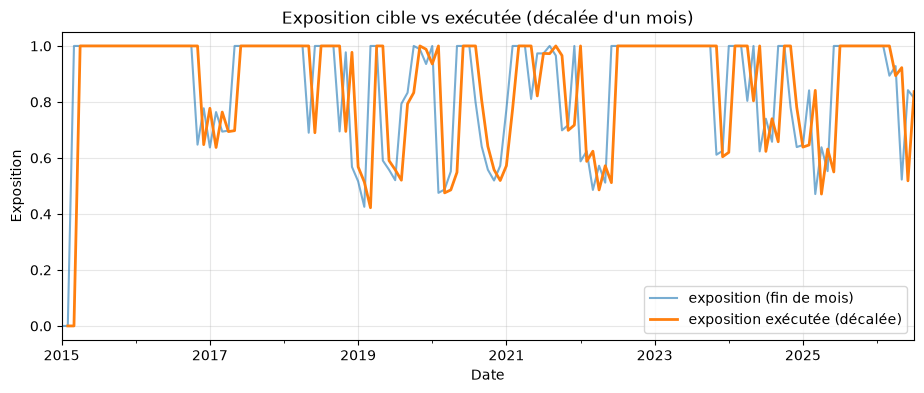

Exposition exécutée — moyenne : 0.852 | min : 0.0 | max : 1.0
Mois d'exposition fortement réduite (<50 %) : 8 / 139


In [6]:
TARGET_VOL, VOL_WINDOW = 0.10, 3
vt_main, vt_bt = vol_targeted_strategy(base_res, TARGET_VOL, VOL_WINDOW, TC)

raw_expo = compute_target_exposure(vols[VOL_WINDOW], TARGET_VOL)   # connue fin de mois
exec_expo = vt_main["executed_exposure"]                           # décalée d'un mois

fig, ax = plt.subplots(figsize=(11, 4))
raw_expo.plot(ax=ax, label="exposition (fin de mois)", alpha=0.6)
exec_expo.plot(ax=ax, label="exposition exécutée (décalée)", linewidth=2)
ax.set_ylim(-0.05, 1.05); ax.set_title("Exposition cible vs exécutée (décalée d'un mois)")
ax.set_ylabel("Exposition"); ax.legend(); ax.grid(True, alpha=0.3); plt.show()

expo_clean = exec_expo.fillna(0.0)
print("Exposition exécutée — moyenne :", round(expo_clean.mean(), 3),
      "| min :", round(expo_clean.min(), 3), "| max :", round(expo_clean.max(), 3))
print("Mois d'exposition fortement réduite (<50 %) :", int((expo_clean < 0.5).sum()), "/", len(expo_clean))

## 7. Poids finaux

Poids Momentum (avant) vs après volatility targeting : les poids d'actifs sont mis à l'échelle par l'exposition, le reste va au cash. Somme = 1, aucun levier, aucun poids négatif.

In [7]:
before = base_res["executed_weights"]
after = vt_main["final_weights"]

comparison_tail = pd.concat(
    {"AVANT (momentum)": before.tail(6).round(3), "APRÈS (vol target)": after.tail(6).round(3)},
    axis=1,
)
print(comparison_tail)
print("\nSomme des poids toujours = 1 :", bool(np.allclose(after.sum(axis=1), 1.0)))
print("Aucun poids négatif :", bool((after.to_numpy() >= -1e-9).all()))
print("Aucune exposition > 100 % :", bool((after.drop(columns=CASH_COLUMN).sum(axis=1) <= 1 + 1e-9).all()))

           AVANT (momentum)             APRÈS (vol target)              
                     CW8.PA ESE.PA CASH             CW8.PA ESE.PA   CASH
Date                                                                    
2026-02-28              1.0    0.0  0.0                1.0  0.000  0.000
2026-03-31              1.0    0.0  0.0                1.0  0.000  0.000
2026-04-30              0.0    0.0  1.0                0.0  0.000  1.000
2026-05-31              0.0    1.0  0.0                0.0  0.923  0.077
2026-06-30              0.0    1.0  0.0                0.0  0.518  0.482
2026-07-31              0.0    1.0  0.0                0.0  0.837  0.163

Somme des poids toujours = 1 : True
Aucun poids négatif : True
Aucune exposition > 100 % : True


## 8. Comparaison des stratégies

Frais 0,10 %. On présente les résultats de façon neutre — pas de sélection automatique du meilleur rendement.

In [8]:
_, mom_pur_bt = momentum_strategy(universe, 12, 1, MA_WINDOW, 1, TC, use_trend=False)
mom_pur_res, _ = momentum_strategy(universe, 12, 1, MA_WINDOW, 1, TC, use_trend=False)
_, mom_pur_vt_bt = vol_targeted_strategy(mom_pur_res, TARGET_VOL, VOL_WINDOW, TC)


def summarise(bt, exposure=None):
    s = performance_summary(bt["Net Return"].dropna(), bt["Equity Curve"], periods_per_year=PPY)
    s["Turnover moy"] = bt["Turnover"].mean()
    s["Coûts cumulés"] = bt["Transaction Cost"].sum()
    s["Expo moy"] = bt["Invested Exposure"].mean()
    s["Mois cash"] = int((bt["Cash Weight"] > 0.999).sum())
    return s


table = {
    "Buy & Hold " + BENCHMARK: performance_summary(bench["Returns"].dropna(), bench["Equity Curve"], periods_per_year=PPY),
    "Mom 12-1 (sans filtre)": summarise(mom_pur_bt),
    "Mom 12-1 + MA10": summarise(base_bt),
    "Mom 12-1 + MA10 + VT": summarise(vt_bt),
    "Mom 12-1 + VT (sans filtre)": summarise(mom_pur_vt_bt),
}
comparison = pd.DataFrame(table).T
comparison.round(4)

,Best Year,CAGR,Coûts cumulés,Expo moy,Final Capital,Max Drawdown,Mois cash,Sharpe,Turnover moy,Volatility,Worst Year
Buy & Hold CW8.PA,0.3234,0.1117,NaN,NaN,33804.1845,-0.1861,NaN,0.8699,NaN,0.1323,-0.1374
Mom 12-1 (sans filtre),0.4126,0.1309,0.0150,0.9065,41568.2676,-0.1764,13.0,0.9990,0.1079,0.1324,-0.1410
Mom 12-1 + MA10,0.4126,0.0872,0.0300,0.7626,26335.8171,-0.1658,33.0,0.8237,0.2158,0.1090,-0.1658
Mom 12-1 + MA10 + VT,0.3511,0.0711,0.0387,0.6637,22151.7500,-0.1493,33.0,0.7480,0.2786,0.0985,-0.1493
Mom 12-1 + VT (sans filtre),0.3511,0.1079,0.0297,0.7246,32759.4165,-0.1322,13.0,0.9987,0.2136,0.1089,-0.0474


## 9. Robustesse

Grille bornée : cible ∈ {6,8,10,12 %}, fenêtre ∈ {3,6,12 mois}, frais ∈ {0 ; 0,10 ; 0,20 ; 0,30 %}. Tableau neutre, sans sélection automatique.

In [9]:
grid_rows = []
for tv in (0.06, 0.08, 0.10, 0.12):
    for w in (3, 6, 12):
        for tc in (0.0, 0.001, 0.002, 0.003):
            vt, bt = vol_targeted_strategy(base_res, tv, w, tc)
            s = performance_summary(bt["Net Return"].dropna(), bt["Equity Curve"], periods_per_year=PPY)
            grid_rows.append({
                "cible_%": tv * 100, "fenetre": w, "frais_%": tc * 100,
                "CAGR_%": s["CAGR"] * 100, "Vol_%": s["Volatility"] * 100, "Sharpe": s["Sharpe"],
                "MaxDD_%": s["Max Drawdown"] * 100, "Expo_moy": bt["Invested Exposure"].mean(),
                "Turnover": bt["Turnover"].mean(), "Capital_final": s["Final Capital"],
            })
grid = pd.DataFrame(grid_rows)
print("Combinaisons :", len(grid))
print("\nVue frais 0,10 % :")
grid[grid["frais_%"] == 0.1].drop(columns="frais_%").round(3).reset_index(drop=True)

Combinaisons : 48

Vue frais 0,10 % :


,cible_%,fenetre,CAGR_%,Vol_%,Sharpe,MaxDD_%,Expo_moy,Turnover,Capital_final
0,6.0,3,5.620,8.161,0.712,-13.123,0.528,0.297,18839.727
1,6.0,6,5.438,7.018,0.791,-9.213,0.487,0.200,18466.649
2,6.0,12,5.643,6.834,0.839,-9.010,0.460,0.162,18886.697
3,8.0,3,6.368,9.111,0.724,-14.353,0.609,0.289,20443.696
4,8.0,6,6.558,8.575,0.785,-12.157,0.593,0.224,20870.582
5,8.0,12,6.955,8.542,0.832,-11.901,0.585,0.191,21789.003
6,10.0,3,7.107,9.849,0.748,-14.930,0.664,0.279,22151.750
7,10.0,6,7.637,9.772,0.804,-14.198,0.676,0.232,23453.307
8,10.0,12,7.756,9.828,0.811,-14.064,0.677,0.210,23756.689
9,12.0,3,7.609,10.285,0.766,-15.157,0.704,0.263,23383.282


In [10]:
fee_sens = grid.groupby("frais_%")["Capital_final"].mean().round(2)
print("Capital final moyen par niveau de frais :"); print(fee_sens)
assert fee_sens.is_monotonic_decreasing, "Plus de frais doit réduire le capital moyen."

Capital final moyen par niveau de frais :
frais_%
0.0    22580.42
0.1    21868.43
0.2    21178.94
0.3    20511.24
Name: Capital_final, dtype: float64


## 10. Graphiques

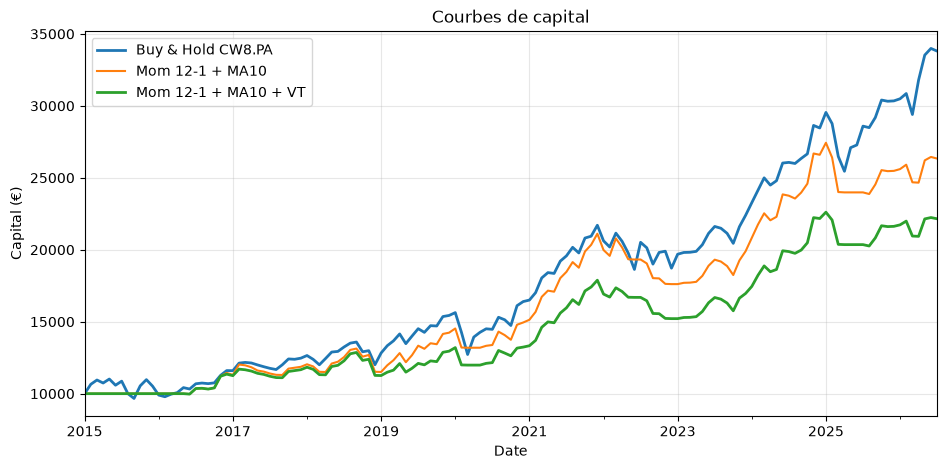

In [11]:
main_equity = vt_bt["Equity Curve"]

fig, ax = plt.subplots(figsize=(11, 5))
bench["Equity Curve"].plot(ax=ax, label="Buy & Hold " + BENCHMARK, lw=2)
base_bt["Equity Curve"].plot(ax=ax, label="Mom 12-1 + MA10")
main_equity.plot(ax=ax, label="Mom 12-1 + MA10 + VT", lw=2)
ax.set_title("Courbes de capital"); ax.set_ylabel("Capital (€)"); ax.legend(); ax.grid(True, alpha=0.3); plt.show()

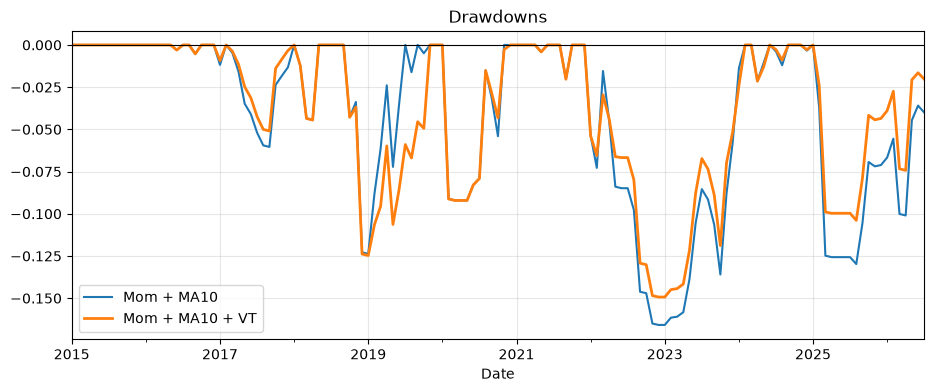

In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
compute_drawdown(base_bt["Equity Curve"]).plot(ax=ax, label="Mom + MA10")
compute_drawdown(main_equity).plot(ax=ax, label="Mom + MA10 + VT", lw=2)
ax.axhline(0, color="black", lw=0.8); ax.set_title("Drawdowns"); ax.legend(); ax.grid(True, alpha=0.3); plt.show()

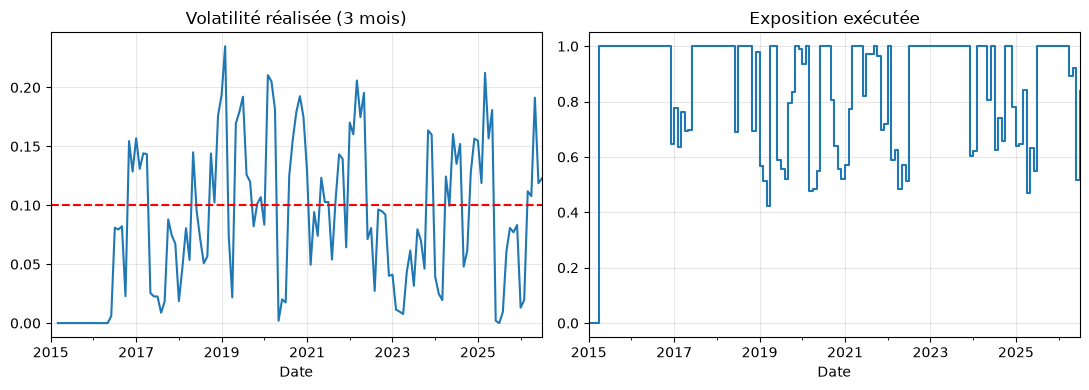

In [13]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
vols[VOL_WINDOW].plot(ax=a1); a1.axhline(0.10, color="red", ls="--")
a1.set_title("Volatilité réalisée (3 mois)"); a1.grid(True, alpha=0.3)
vt_main["executed_exposure"].fillna(0).plot(ax=a2, drawstyle="steps-post")
a2.set_ylim(-0.05, 1.05); a2.set_title("Exposition exécutée"); a2.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

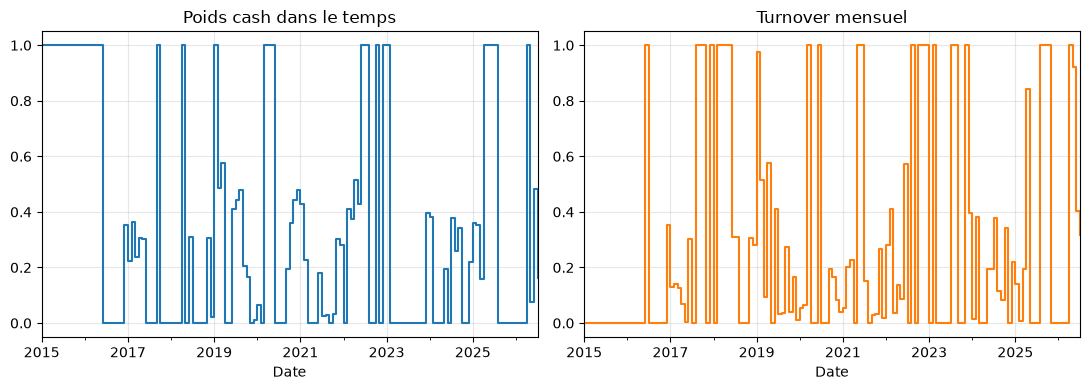

In [14]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
vt_bt["Cash Weight"].plot(ax=a1, drawstyle="steps-post", color="#1f77b4")
a1.set_ylim(-0.05, 1.05); a1.set_title("Poids cash dans le temps"); a1.grid(True, alpha=0.3)
vt_bt["Turnover"].plot(ax=a2, drawstyle="steps-post", color="#ff7f0e")
a2.set_title("Turnover mensuel"); a2.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

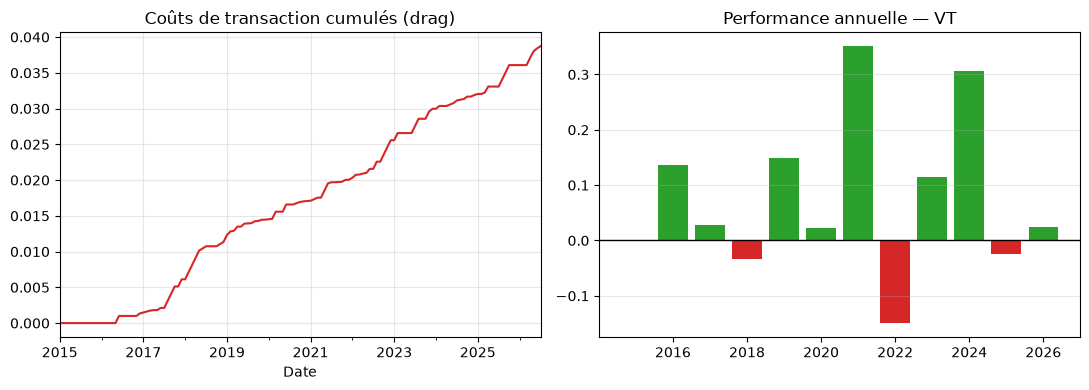

In [15]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
vt_bt["Transaction Cost"].cumsum().plot(ax=a1, color="#d62728")
a1.set_title("Coûts de transaction cumulés (drag)"); a1.grid(True, alpha=0.3)
annual = yearly_returns(vt_bt["Net Return"].dropna())
a2.bar(annual.index.year, annual.values, color=["#2ca02c" if v >= 0 else "#d62728" for v in annual.values])
a2.axhline(0, color="black", lw=1); a2.set_title("Performance annuelle — VT"); a2.grid(True, axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 11. Contrôles finaux

In [16]:
fw = vt_main["final_weights"]
w = fw.to_numpy()

# Exposition et poids valides
assert (w >= -1e-9).all() and (w <= 1 + 1e-9).all(), "Poids hors [0, 1]."
assert np.allclose(fw.sum(axis=1), 1.0), "Somme des poids != 1."
assert (vt_main["executed_exposure"].dropna().between(0, 1)).all(), "Exposition hors [0, 1]."

# Anti-look-ahead : exposition exécutée = exposition cible décalée d'un mois.
tgt, exe = vt_main["target_exposure"], vt_main["executed_exposure"]
assert np.allclose(exe.iloc[1:].fillna(-9).to_numpy(), tgt.iloc[:-1].fillna(-9).to_numpy()), "Décalage d'exposition incorrect."
assert fw.iloc[0][CASH_COLUMN] == 1.0, "Première période non 100% cash."

# Cash cohérent, capital positif, drawdown <= 0
assert np.allclose(vt_bt["Cash Weight"] + vt_bt["Invested Exposure"], 1.0), "Cash + investi != 1."
assert (vt_bt["Equity Curve"] > 0).all(), "Capital non positif."
assert (compute_drawdown(vt_bt["Equity Curve"]) <= 1e-9).all(), "Drawdown positif."

# Frais plus élevés ne peuvent pas améliorer le capital net (allocations identiques).
_, bt_lo = vol_targeted_strategy(base_res, TARGET_VOL, VOL_WINDOW, 0.0)
_, bt_hi = vol_targeted_strategy(base_res, TARGET_VOL, VOL_WINDOW, 0.003)
assert bt_lo["Equity Curve"].iloc[-1] >= bt_hi["Equity Curve"].iloc[-1] - 1e-9, "Les frais ne devraient pas améliorer le capital."

# Reproductibilité
_, bt_again = vol_targeted_strategy(base_res, TARGET_VOL, VOL_WINDOW, TC)
assert np.allclose(bt_again["Equity Curve"].to_numpy(), vt_bt["Equity Curve"].to_numpy()), "Non reproductible."

assert not main_equity.isna().any() and not vt_bt["Net Return"].isna().any(), "NaN dans les sorties finales."
print("Tous les contrôles passent.")

Tous les contrôles passent.


In [17]:
print("Projet 3 — Volatility Targeting validé techniquement.")
print("Validation technique ne signifie pas recommandation d'investissement réel.")

Projet 3 — Volatility Targeting validé techniquement.
Validation technique ne signifie pas recommandation d'investissement réel.
